In [1]:
import os

# List all files and directories in the root of the Kaggle environment
for dirname, _, filenames in os.walk('/kaggle/'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/lib/kaggle/gcp.py
/kaggle/input/datasets/co1d7era/mixedtype-wafer-defect-datasets/Wafer_Map_Datasets.npz
/kaggle/input/datasets/co1d7era/mixedtype-wafer-defect-datasets/Description.pdf


In [2]:
import os
from os.path import join
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Input, models
from tensorflow.keras.utils import to_categorical

from sklearn.model_selection import KFold, cross_val_score,train_test_split

import matplotlib.pyplot as plt

datapath = join('/kaggle/input/datasets/co1d7era/mixedtype-wafer-defect-datasets/Wafer_Map_Datasets.npz')
print(datapath)

2026-08-06 02:16:48.292283: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1785982608.585824      58 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1785982608.663624      58 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1785982609.341153      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1785982609.341205      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1785982609.341210      58 computation_placer.cc:177] computation placer alr

/kaggle/input/datasets/co1d7era/mixedtype-wafer-defect-datasets/Wafer_Map_Datasets.npz


In [3]:
import numpy as np

data = np.load('/kaggle/input/datasets/co1d7era/mixedtype-wafer-defect-datasets/Wafer_Map_Datasets.npz')

X = data['arr_0']
Y = data['arr_1']

print(X.shape)
print(Y.shape)

(38015, 52, 52)
(38015, 8)


In [4]:
single_ranges = [
    (12000,12999),   # Center
    (24000,24999),   # Donut
    (25000,25999),   # Edge-Loc
    (26000,26999),   # Edge-Ring
    (32000,32999),   # Loc
    (34866,35014),   # Near-Full
    (37015,38014),   # Scratch
    (33000,33865)    # Random
]

indices = []

for start, end in single_ranges:
    indices.extend(range(start, end+1))

indices = np.array(indices)

X = X[indices]
Y = Y[indices]

print(X.shape)
print(Y.shape)

(7015, 52, 52)
(7015, 8)


In [5]:
remap = [0,1,2,3,4,7,6,5]

Y = Y[:, remap]

y = np.argmax(Y, axis=1)

In [6]:
import cv2

X_resized = np.array([
    cv2.resize(img.astype(np.uint8),
               (32,32),
               interpolation=cv2.INTER_NEAREST)
    for img in X
])

print(X_resized.shape)

(7015, 32, 32)


In [7]:
X_encoded = np.zeros((len(X_resized),32,32,3))

for w in range(len(X_resized)):
    for i in range(32):
        for j in range(32):

            value = int(X_resized[w,i,j])

            if value < 3:
                X_encoded[w,i,j,value] = 1

print(X_encoded.shape)

(7015, 32, 32, 3)


In [8]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

y_cat = to_categorical(y, num_classes=8)

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y_cat,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(5612, 32, 32, 3)
(1403, 32, 32, 3)


In [9]:
from tensorflow.keras import layers, models
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical
import tensorflow as tf

# Define the Differential Attention Layer
class DifferentialAttention(layers.Layer):
    def __init__(self, embed_dim, num_heads, lambda_init=0.8):
        super(DifferentialAttention, self).__init__()
        self.num_heads = num_heads
        self.embed_dim = embed_dim
        assert embed_dim % num_heads == 0, "Embedding dimension must be divisible by number of heads."

        self.projection_dim = embed_dim // num_heads
        self.query_dense = layers.Dense(embed_dim)
        self.key_dense = layers.Dense(embed_dim)
        self.value_dense = layers.Dense(embed_dim)
        self.lambda_param = tf.Variable(lambda_init, trainable=True, dtype=tf.float32)

    def split_heads(self, x, batch_size):
        """Split the last dimension into (num_heads, projection_dim)."""
        x = tf.reshape(x, (batch_size, -1, self.num_heads, self.projection_dim))
        return tf.transpose(x, perm=[0, 2, 1, 3])  # (batch, num_heads, seq_len, projection_dim)

    def compute_attention(self, query, key, value):
        """Compute scaled dot-product attention."""
        matmul_qk = tf.matmul(query, key, transpose_b=True)  # (batch, num_heads, seq_len, seq_len)
        d_k = tf.cast(tf.shape(key)[-1], tf.float32)
        scaled_attention_logits = matmul_qk / tf.sqrt(d_k)
        attention_weights = tf.nn.softmax(scaled_attention_logits, axis=-1)  # (batch, num_heads, seq_len, seq_len)
        return tf.matmul(attention_weights, value)  # (batch, num_heads, seq_len, projection_dim)

    def call(self, inputs):
        batch_size = tf.shape(inputs)[0]

        # Linear projections for Q, K, V
        query = self.query_dense(inputs)
        key = self.key_dense(inputs)
        value = self.value_dense(inputs)

        # Split Q into Q1 and Q2, and K into K1 and K2
        query = self.split_heads(query, batch_size)
        key = self.split_heads(key, batch_size)
        value = self.split_heads(value, batch_size)

        q1, q2 = tf.split(query, num_or_size_splits=2, axis=-1)  # Split last dim into two
        k1, k2 = tf.split(key, num_or_size_splits=2, axis=-1)

        # Compute differential attention
        attn1 = self.compute_attention(q1, k1, value)
        attn2 = self.compute_attention(q2, k2, value)

        diff_attn = attn1 - self.lambda_param * attn2

        # Concatenate attention heads and project
        diff_attn = tf.transpose(diff_attn, perm=[0, 2, 1, 3])  # (batch, seq_len, num_heads, projection_dim)
        concat_diff_attn = tf.reshape(diff_attn, (batch_size, -1, self.embed_dim))  # (batch, seq_len, embed_dim)

        return concat_diff_attn


# Input layer
input_layer = Input(shape=(32, 32, 3), name="Input_Layer")

# Convolutional and Pooling layers
x = layers.Conv2D(32, (3, 3), activation='relu', padding='same', name="Conv1")(input_layer)
x = layers.BatchNormalization(name="BatchNorm1")(x)
x = layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2), name="MaxPool1")(x)

x = layers.Conv2D(64, (3, 3), activation='relu', padding='same', name="Conv2")(x)
x = layers.BatchNormalization(name="BatchNorm2")(x)
x = layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2), name="MaxPool2")(x)

x = layers.Conv2D(128, (3, 3), activation='relu', padding='same', name="Conv3")(x)
x = layers.BatchNormalization(name="BatchNorm3")(x)
x = layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2), name="MaxPool3")(x)

# Differential Attention Layer
x = DifferentialAttention(embed_dim=64, num_heads=16, lambda_init=0.8)(x)
x._name = 'diffAtten'
x = layers.GlobalAveragePooling1D()(x)

# Flatten layer
x = layers.Flatten(name="Flatten")(x)

# Fully connected layers
x = layers.Dropout(0.3, name="Dropout1")(x)
x = layers.Dense(32, activation='relu', name="Dense_128")(x)
x = layers.Dropout(0.2, name="Dropout2")(x)

# Output layer
output_layer = layers.Dense(8, activation='softmax', name="Output_Layer")(x)

# Define the model
model = models.Model(inputs=input_layer, outputs=output_layer, name="Differential_Model")

# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Display the model summary
model.summary()


2026-08-06 02:17:15.567220: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "Differential_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv1 (Conv2D)                  │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BatchNorm1 (BatchNormalization) │ (None, 32, 32, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPool1 (MaxPooling2D)         │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv2 (Conv2D)                  │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BatchNorm2 (BatchNormalization) │ (None, 16, 16, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPool2 (MaxPooling2D)         │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv3 (Conv2D)                  │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BatchNorm3 (BatchNormalization) │ (None, 8, 8, 128)      │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPool3 (MaxPooling2D)         │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ differential_attention          │ (None, None, 64)       │        24,768 │
│ (DifferentialAttention)         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Flatten (Flatten)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout1 (Dropout)              │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_128 (Dense)               │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout2 (Dropout)              │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 8)              │           264 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,256 (473.66 KB)

 Trainable params: 120,808 (471.91 KB)

 Non-trainable params: 448 (1.75 KB)

In [10]:
history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    # callbacks=callbacks
)

Epoch 1/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 14s 68ms/step - accuracy: 0.6799 - loss: 0.8614 - val_accuracy: 0.0784 - val_loss: 2.0897
Epoch 2/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 9s 65ms/step - accuracy: 0.8989 - loss: 0.2932 - val_accuracy: 0.3874 - val_loss: 1.8489
Epoch 3/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 9s 65ms/step - accuracy: 0.9332 - loss: 0.2109 - val_accuracy: 0.8673 - val_loss: 0.3897
Epoch 4/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 9s 65ms/step - accuracy: 0.9583 - loss: 0.1327 - val_accuracy: 0.9225 - val_loss: 0.2364
Epoch 5/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 9s 65ms/step - accuracy: 0.9586 - loss: 0.1201 - val_accuracy: 0.9590 - val_loss: 0.1326
Epoch 6/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 9s 65ms/step - accuracy: 0.9597 - loss: 0.1207 - val_accuracy: 0.9590 - val_loss: 0.1178
Epoch 7/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 9s 65ms/step - accuracy: 0.9681 - loss: 0.0925 - val_accuracy: 0.9608 - val_loss: 0.1476
Epoch 8/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 9s 65ms/step - accuracy: 0.9800 - loss: 0.0622 - val_acc

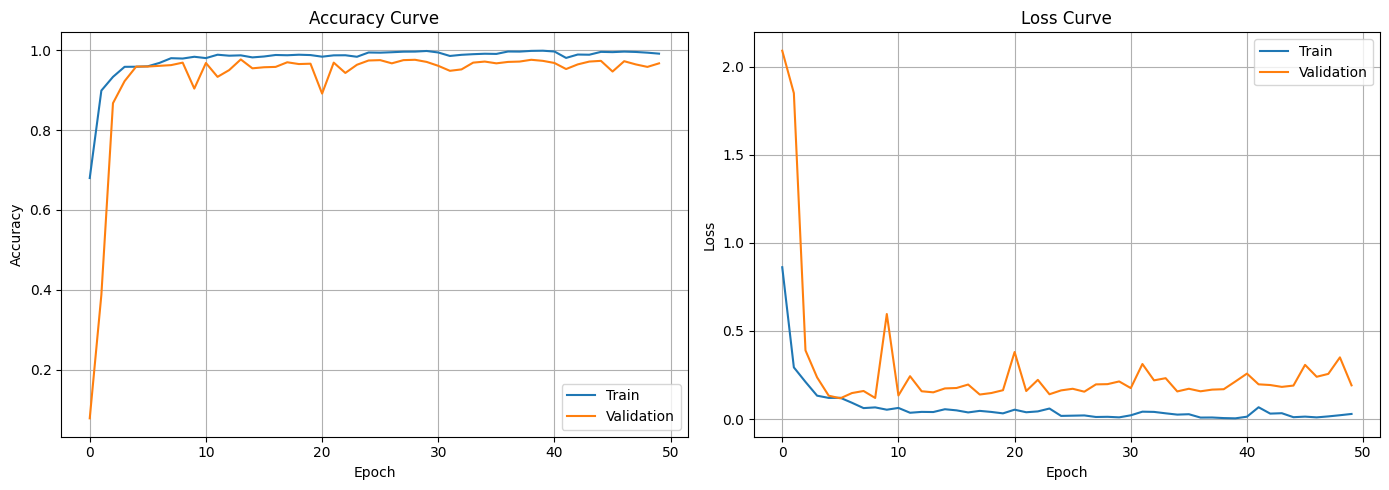

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14,5))

# Accuracy
axes[0].plot(history.history['accuracy'], label='Train')
axes[0].plot(history.history['val_accuracy'], label='Validation')
axes[0].set_title('Accuracy Curve')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)

# Loss
axes[1].plot(history.history['loss'], label='Train')
axes[1].plot(history.history['val_loss'], label='Validation')
axes[1].set_title('Loss Curve')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [12]:
test_loss, test_acc = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("Test Accuracy:", test_acc)

44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9736 - loss: 0.1391
Test Accuracy: 0.9736279249191284


In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix
)

import numpy as np

# =====================================================
# PREDICTIONS
# =====================================================

y_prob = model.predict(X_test)

# Predicted class index
y_pred = np.argmax(y_prob, axis=1)

# True class index
y_true = np.argmax(y_test, axis=1)

# =====================================================
# METRICS
# =====================================================

acc = accuracy_score(y_true, y_pred)

precision_macro = precision_score(
    y_true, y_pred,
    average='macro',
    zero_division=0
)

recall_macro = recall_score(
    y_true, y_pred,
    average='macro',
    zero_division=0
)

macro_f1 = f1_score(
    y_true, y_pred,
    average='macro',
    zero_division=0
)

precision_weighted = precision_score(
    y_true, y_pred,
    average='weighted',
    zero_division=0
)

recall_weighted = recall_score(
    y_true, y_pred,
    average='weighted',
    zero_division=0
)

weighted_f1 = f1_score(
    y_true, y_pred,
    average='weighted',
    zero_division=0
)

balanced_acc = balanced_accuracy_score(
    y_true, y_pred
)

kappa = cohen_kappa_score(
    y_true, y_pred
)

mcc = matthews_corrcoef(
    y_true, y_pred
)

# =====================================================
# PRINT RESULTS
# =====================================================

print("\nEvaluation Results")
print("="*60)

print(f"Accuracy            : {acc:.4f}")
print(f"Balanced Accuracy   : {balanced_acc:.4f}")

print(f"Macro Precision     : {precision_macro:.4f}")
print(f"Macro Recall        : {recall_macro:.4f}")
print(f"Macro F1-score      : {macro_f1:.4f}")

print(f"Weighted Precision  : {precision_weighted:.4f}")
print(f"Weighted Recall     : {recall_weighted:.4f}")
print(f"Weighted F1-score   : {weighted_f1:.4f}")

print(f"Cohen's Kappa       : {kappa:.4f}")
print(f"MCC                 : {mcc:.4f}")

44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step

Evaluation Results
Accuracy            : 0.9736
Balanced Accuracy   : 0.9763
Macro Precision     : 0.9600
Macro Recall        : 0.9763
Macro F1-score      : 0.9671
Weighted Precision  : 0.9746
Weighted Recall     : 0.9736
Weighted F1-score   : 0.9738
Cohen's Kappa       : 0.9694
MCC                 : 0.9695


In [14]:
class_names = [
    'Center',
    'Donut',
    'Edge-Loc',
    'Edge-Ring',
    'Loc',
    'Random',
    'Scratch',
    'Near-full'
]

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Center     0.9949    0.9800    0.9874       200
       Donut     1.0000    1.0000    1.0000       200
    Edge-Loc     0.9590    0.9350    0.9468       200
   Edge-Ring     0.9565    0.9900    0.9730       200
         Loc     0.9949    0.9750    0.9848       200
      Random     1.0000    0.9653    0.9824       173
     Scratch     0.9415    0.9650    0.9531       200
   Near-full     0.8333    1.0000    0.9091        30

    accuracy                         0.9736      1403
   macro avg     0.9600    0.9763    0.9671      1403
weighted avg     0.9746    0.9736    0.9738      1403



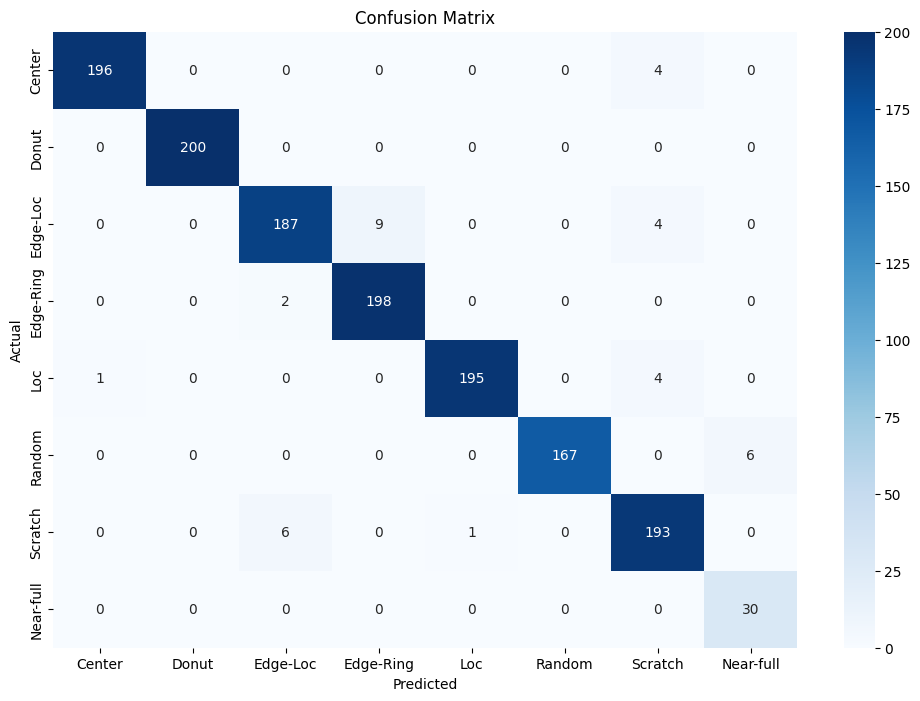

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12,8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [16]:
import pandas as pd
import numpy as np

class_names = [
    'Center',
    'Donut',
    'Edge-Loc',
    'Edge-Ring',
    'Loc',
    'Random',
    'Scratch',
    'Near-full'
]

counts = np.bincount(y)

stats_df = pd.DataFrame({
    'Class': class_names,
    'Samples': counts
})

stats_df['Percentage'] = (
    stats_df['Samples'] / stats_df['Samples'].sum()
) * 100

stats_df = stats_df.sort_values(
    'Samples',
    ascending=False
)

print(stats_df)

       Class  Samples  Percentage
0     Center     1000   14.255167
1      Donut     1000   14.255167
2   Edge-Loc     1000   14.255167
3  Edge-Ring     1000   14.255167
4        Loc     1000   14.255167
6    Scratch     1000   14.255167
5     Random      866   12.344975
7  Near-full      149    2.124020


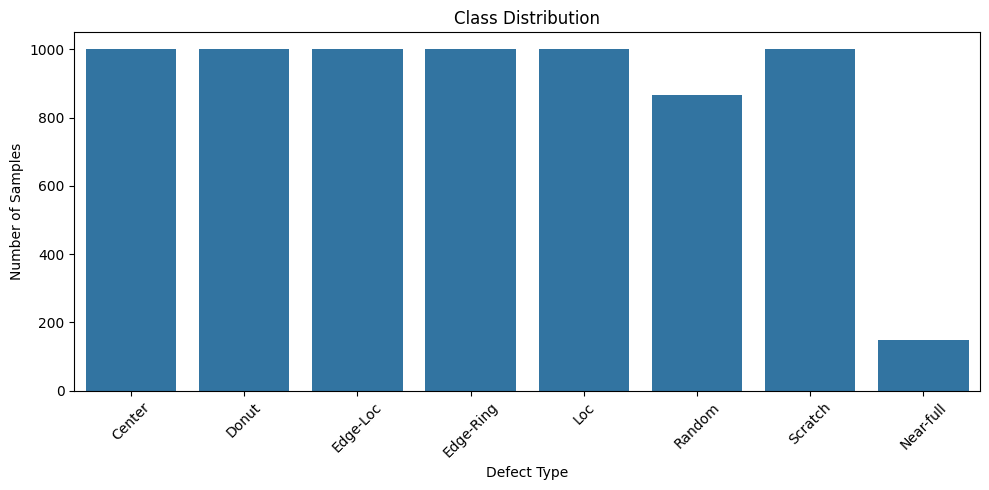

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

sns.barplot(
    x=class_names,
    y=counts
)

plt.title('Class Distribution')
plt.xlabel('Defect Type')
plt.ylabel('Number of Samples')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [18]:
print("Dataset Statistics")
print("="*40)

print("Total Samples :", len(X_encoded))
print("Image Size    :", X_encoded.shape[1:3])
print("Channels      :", X_encoded.shape[3])
print("Classes       :", len(class_names))

print("\nClass Counts")
for c,n in zip(class_names, counts):
    print(f"{c:<12}: {n}")

Dataset Statistics
Total Samples : 7015
Image Size    : (32, 32)
Channels      : 3
Classes       : 8

Class Counts
Center      : 1000
Donut       : 1000
Edge-Loc    : 1000
Edge-Ring   : 1000
Loc         : 1000
Random      : 866
Scratch     : 1000
Near-full   : 149


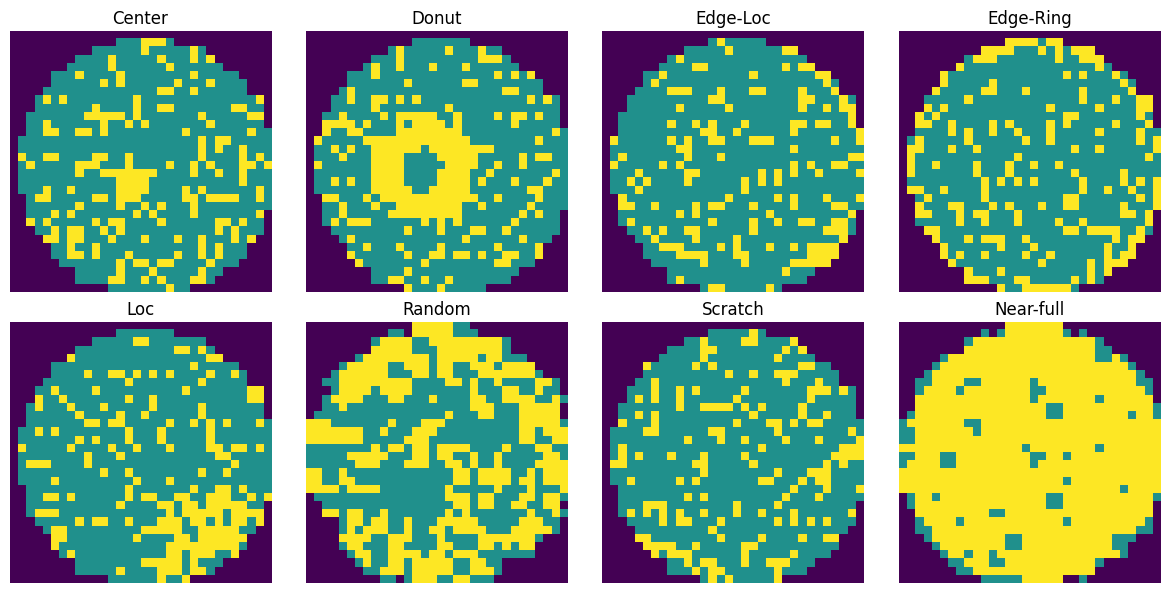

In [19]:
fig, axes = plt.subplots(2,4, figsize=(12,6))

for cls in range(8):

    idx = np.where(y == cls)[0][0]

    axes[cls//4, cls%4].imshow(
        np.argmax(X_encoded[idx], axis=-1),
        cmap='viridis'
    )

    axes[cls//4, cls%4].set_title(class_names[cls])
    axes[cls//4, cls%4].axis('off')

plt.tight_layout()
plt.show()